# Day 1
This Lab Journal describes our way in measuring brownian motion under the microscope and using the quantitative results to find another quantity or verify something else. 

We attended the introduction presentation.

We initialised our github repository for collaboration at <https://github.com/HiperLoop/LAB>.

We looked into the sample-preparation. The liquids we have at our disposal are monodisperse polystyrene microspheres of the sizes of 0.5-2 $\mu\text{m}$ who are collodial suspensed in water and concentrations of 1%, 0.5%, 0.1%, 0.05%, and 0.01%. To prepare a sample, we are pipetting 1-2 drops on a sample holder and cover it with a glas plane. Importantly, we have to mix the solution before we are taking drops out, since the particles would drop within minutes to the ground. Then we transport it back to the microscope.

In this experiment, we are using the Bleeker Microscope with an external light source and the DinoExe CCD Camera on top of the microscope to take videos of samples under the microcope. We started by trying to setup the camera and install all the necessary software. We ran into problems with Dino capture 3.0 so we installed the 2.0 version and that worked for us. We are therefore now able to live-monitor the video of the microscope on our laptops. We have also found out that we can set the saving location for the data (videos and pictures) directly in our directory that is shared via githubg so that we both have access to the files.

We tried our first setup. We had a lot of trouble pointing the light in the right direction to see any image from the microscope. We then found out that the magnification lenses on the microscope do not produce any image. We investigated this with the TA. In the end we decided to switch microscopes as it seemed to be an issue with the lenses.

For the light source, after experimenting with a flexible light source, for the sake of consistency we decided that we will put everything on the holds so that we can focus the light and keep a constant distance between light source and lens. We then tried to focus the light so that the sample lies in the focus point of the other lens in the Bleeker microscope, which proved to be quite difficult. We are using the strongest lens whose attributes are not further quantified.

Image of our first setup.

![Image of our first setup](<Lab Journal/Screenshot 2026-10-30 145737.png>)

Eventually, we noticed that using the focus lense did not enhace our image in any way therefore we decided to use the light directly on the mirror of the microscope since that produced sufficient ligting to achieve good results. After that plus switching microscopes we were able to produce our first good images of moving particles.

![alt text](<Lab Journal/A003-20261007_153704.jpg>)

We reproduced the results with the different microscope strenghts, but eventually settled on N40 x 0.65 since this seemed to be the best tradeoff between sample size and clearness of movement. We took a first video that we wanted to use to start with trackpy since we wanted to be sure that we can quantify the quality of the videos we were taking. 

We started by using the first frame of the video. The first step is to picturing the image in a grey-scale. This is especially important because that means that the colors that we are seeing in the image and that are clearly recognizable for us, will not be benificial for trackpy at all. We then used the build-in functions of trackpy tp.locate to find all of the particles and plotted the localized particles with the red circles as in the example document (https://soft-matter.github.io/trackpy/dev/tutorial/walkthrough.html). 
Here, one can use two different initial parameters for the localize function, the minimal mass necessary for something to be considered a particle and the assumed feature size. For our first video, we settled on 2000 as the minimum mass since this filtered out potential noise that was seen as a particle before. The feature size worked best for us when we used 19. 

This is clearly not yet fully functional but was good enough for us to see a first result. For future videos we assume that this will have to be refined individually. Due to time constraints, this is where we are ending for the first day. 

**Note** we have been lacking in putting the WIP code into our labjournal. This is why some of them have been added or edited later on so that they also work within the notebook. This is also why the package import is much bigger then immediately needed but so that everything is at one point.

In [ ]:
#EDITED LATER: packages we will be using over the course of this project
import os
import typing
import matplotlib as mpl
import matplotlib.pyplot as plt
import pims
import trackpy as tp
from pandas import DataFrame, Series
import numpy as np
import pandas as pd
from scipy.constants import Boltzmann
from scipy.optimize import curve_fit

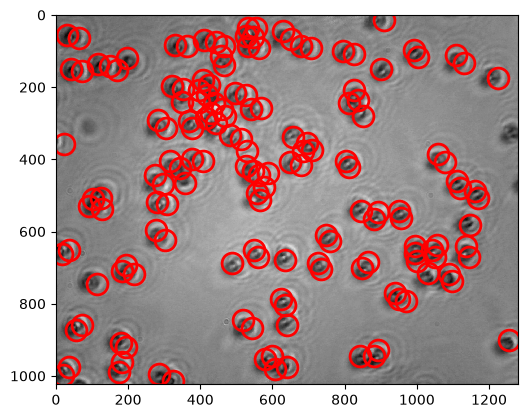

<Axes: >

In [20]:
def gray(image: Series) -> Series:
    '''Make image monochromatic by just taking the green channel in the RGB values.'''
    return image[:, :, 1]

def loadImageAsGrey(image_name: str):
    '''Load an image and keep only the green channel.'''
    frame = pims.open(image_name)[0]   # first (and only) frame, an array of shape (height, width, 3)
    return frame[:, :, 1]

image=loadImageAsGrey('Lab Journal\\A003-20261007_153704.jpg')
f = tp.locate(image, 19, invert=True, minmass=2000)
tp.annotate(f, image)

# Day 2

We tried to get the microscope setup working the way we had it last time. After discussion with the TA, we decided that the lack of sharpness in the image above is most likely due to us not using a lens to bundle the light, which is why we tried to bundle our light again with a setup similar to the picture above with a lens and a light source, where we again used the strongest lens to bundle the light as much as possible so that we have a strong light source.
Finding particles this time proved to be significantly more difficult than we initially anticipated. We tried numerus samples, tried to utilize the different magnifications and different light sources but nothing helped anything. Eventually, we found out that both of the microscopes we were using had a problem. The first one had a broken magnification lens, while the second one had a problem in the eye channel. Both of these resulted in us not being able to measure anything. Since it is statistically extremely unlikely that we get our hands on two broken microscopes, we were sure that this was a user problem and spent a solid 2.5 hours on trying everything. Eventually, after receiving a third microscope we were able to get an image within minutes. This image is shown below.

![alt text](<Lab Journal/A006-20261009_122538.jpg>)

We have added a function in our code that can slice the videos in the seperate images so that we can use the abovementioned functions for every frame. 
The instructions state that for the video to be good, you have change manually in DinoCapture the video resolution to 640x480 (HS). We forgot to do this for our sample video, which is why the tracking did not work great. After correcting for that, the tracking was still not perfectly seeing the values. However, due to the enourmous time-loss, the troubleshooting had to be postponed to the next session.

In [ ]:
VIDEO_PATH: str = './data/Adam Data/Video/'

def loadFramesFromVideo(video_name: str) -> Series:
    '''Load all video frames and convert them to monochrome.'''
    return gray(pims.open(f'{VIDEO_PATH}{video_name}'))

def processFrames(frames: Series, feature_size: int, minmass: int, show_plot: bool = False) -> DataFrame:
    '''Annnotate all frames with detected particles.'''
    tp.quiet()
    processed_frames: DataFrame = tp.batch(list(frames), feature_size, invert=True, minmass=minmass)
    if show_plot: tp.annotate(processed_frames, frames[0])
    return processed_frames


# Day 3

We set up the microscope again, this time it took much less time. 

Our goal for today is to get a setup, eg. code that can work directly with recorded videos, that is capable of analysing data in a usefull manner so that we can think about what we would be capable of researching for our project. Naturally, this is the wrong order in comparision to a normal experiment, but it also seems to be in the nature of how the problem of this experiment is being posed. 

To make sure that we can do that as well, we tried a sample with smaller particles for the first time. We switched from observing the 2 micrometer particles to 500 nanometer particles, while keeping the concentration the same at 0.1%. We tried using the biggest magnification to see the particles but struggled to setup the microscope and lightsource so that we can see the particles. Since we also saw from other groups (and confirmed ourselves later), the magnification is sufficient to track particles of all available sizes so we decided that we will stick to the N40 x65, therefore the second highest magnification available to us. We are planing on keeping that constant for the rest of the experiment so that we can also properly compare the length measurements.

We then took a few first videos to test our tracking on. We realised that since we are using trackpy with a grey-scale, the white dots in the middle of our samples are actually disturbing the measurement, since it is assumed to be background. This is why we tried to alter our image in a way that the particles are slightly more unsharp, but more monochromatic and therefore easier to be tracked. Below, we have used the top format and not the bottom.

![alt text](<Lab Journal/A009-20261014_143252.jpg>)

![alt text](<Lab Journal/A010-20261014_143259.jpg>)

There are two variables that Trackpy gets from us that are variable and define what is to be tracked, namely the minimum mass and the estimated feature size in pixels. For this, we compared the same image with different parameters and visualized the particles that got detected. For the minmass, we tried to this time take a bit more of a rigourus approach, since our image was much clearer than on day one. We therefore used a mass histogram to look into what might be noise and what are actual particles:

[Text(0.5, 0, 'mass'), Text(0, 0.5, 'count')]

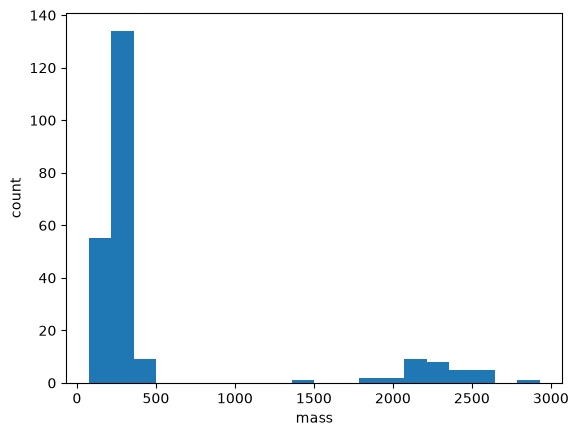

In [25]:
image=loadImageAsGrey('Lab Journal/A009-20261014_143252.jpg')
f = tp.locate(image, 19, invert=True, minmass=0)

fig, ax = plt.subplots()
ax.hist(f['mass'], bins=20)

ax.set(xlabel='mass', ylabel='count')

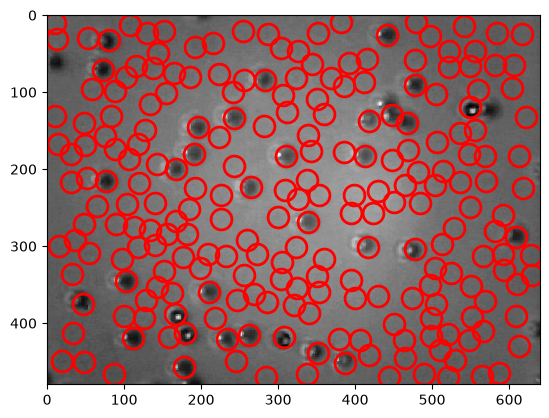

<Axes: >

In [26]:
tp.annotate(f, image)

Therefore, we set the minimum mass at 1500 for the 2 micrometer samples on this amplification, which we analysed out of the histrogram. by obsseving at what mass the majority of particles is concentrated. The result is much more clearly only looking at the relevant particles. 

[Text(0.5, 0, 'mass'), Text(0, 0.5, 'count')]

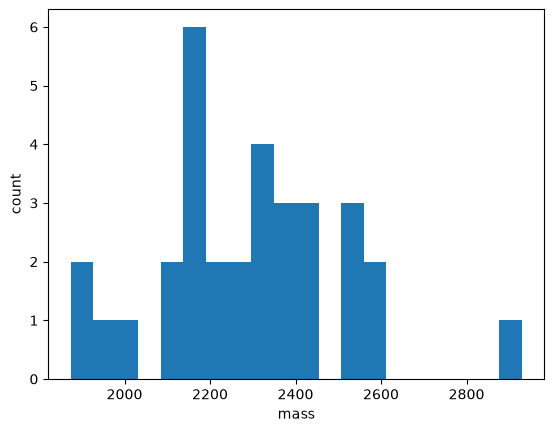

In [27]:
f = tp.locate(image, 19, invert=True, minmass=1500)

fig, ax = plt.subplots()
ax.hist(f['mass'], bins=20)

ax.set(xlabel='mass', ylabel='count')

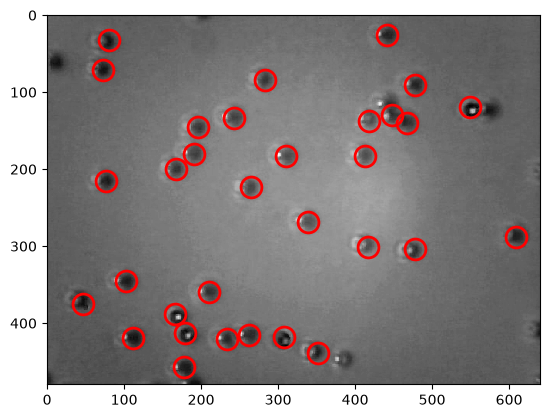

<Axes: >

In [28]:
tp.annotate(f, image)


Clearly, there are also some particles that are not being detected. We decided to deal with that in a quite rigoros way by using the trackpy function filter_stubs, where we can define the minimum number of frames that a particle has to be in to contribute towards the trajectories. We set this to be over the course of the whole video, therefore we are only counting particles that are being tracked for in every single frame. This will most likely make our life easier when it comes further data analysis since this means that there is data for every particle at every frame. 

Currently, we are still just taking test measuremetns to get the setup running. As soon as we start to take measurements that we want to use in our final result, we will have to think of a way to store the data in a better way then just taking videos.

However, the first next step was using the micrometer ruler provide to calibrate our micrometer to pixel ration. We measured the length between lines at a distance of 80 micrometers to be 616 pixels with the lines being 16px wide, from which we get the value with uncertainty as $616 \pm 16$ px. The uncertainty hereby is the width of one small line, since we assume that this is what we could be off by not putting the markers exactly in the middle, the milimeter measurement device being off or the whole image being slightly rotated. The mpp calibration is then $\frac{80}{616} = 0.130 \pm 0.003 \mu\text{m/px}$. We get the uncertainty from the relative uncertainty, which is $\frac{16}{616} \approx 0.02597$. The absolute uncertainty is then $\frac{80}{616} \cdot 0.02597 \approx 0.003$. 

![alt text](<Lab Journal/Screenshot 2026-10-30 121942.png>)

![alt text](<Lab Journal/Screenshot 2026-10-30 122206.png>)

# Day 4
## Plan of Work TODOS Here: write down why everything works as presented here and find some code for it
We decided that we want to find the viscosity of the samples we are given. We are calculating this by using the Stokes-Einstein-Relation:
$$
D = \frac{k_BT}{6\pi\mu a},
$$
For this, we therefore have to find the diffusion constant $D$. 

Last time we got the code working and got our first result for the viscosity calculation. Our research question got refined to "Does the viscosity of the samples depend on the particle size" Today we plan on taking multiple videos with potentially differently-sized particles to properly calculate the viscosity of the samples. Our hypothesis is that without the particles bumping into each other, the viscosity should stay constant for the different samples.  
The following step-by-step scheme can be applied: 
1. Measurement: Taking videos of the diffusion of samples with different particle size
2. Data analysis of one sample: 
    1. Analysing the trajectories of the particles and storing them as an array
    2. Calculating the mean displacement of all of the particles per timestep 
    3. We are then plotting the mean displacement against the time. Due to the relation $D=\frac{\text{d}<R^2>}{\text{dt}}=\frac{<R^2>}{\Delta t}$, if we do a linear fit through that, the slope will be the diffusion constant
    4. We are measuring these diffusion constants for different particle sizes and plot them against the reciprocal of the particle size.Using the Stokes–Einstein–Sutherland relation $\frac{k_B T}{6 \pi \eta r}$, we can see that these two should give a linear relation so we will make a fit through them and assume the slope to be $\eta$. 
    5. In case the linear fit clearly does not work, we can see our hypothesis to be disproven.

#### Uncertainties
We are currently thinking about the following uncertainties: 

1. Uncertainty in the transformation between pixels and SE units due to the ruler 
2. Drift / Turbulances in the sample --> corrected by tp.compute_drift and tp.substract_drift for symetries between the particles
2. Uncertainty in the tracking of the particles --> change of particle got accounted for 
2. Uncertainty due to particles bumping into each other --> tried to be corrected by reducing the concentration until it does not happen again
3. The Randomness of the motion
4. Uncertainty in the time it takes for one frame
5. Uncertainty in the lab value for the particle size 
6. Uncertainty in room temperature

These are all of the experimental uncertainties we can think of. These will give us total uncertainties for  $<R^2>$, $\Delta t$, and $a$. The first two will be passed on with the fit for $D$ to produce a new uncertainty, which can then be combined with $a$ in our second fit so that we in the end get an uncertainty for $\eta$.  

We started taking samples and were slightly disrupted in that since we had to re-setup our light source. We were once again going with the strongest lense available to us binding the lights so that the sample is in the focus. Nevertheless, our TrackPy showed to be quite good at tracking the big particles which we could verify by checking whether they got tracked for every single frame.

We tried the same measuring method for very small particles. We realised that for high concentration with the current settings we were not able to track them consistently since per measurement with about 35 particles, there were only 1 or 2 that survived the whole measurement period. We were using a few methods to try to refine our image further, such as increasing the contrast artificially within dinocapture itself and changing how much our light is being focussed however decided that it is better if all measurements are taken in one session with the exact same setup, which is why we postponed that to the next session.

# Day 5

Today, our main goal is to take all the samples in one go so that they are comparable when it comes to lighting setup. 
We started with the biggest particles but the lowest concentration so that in the end we can have the same concentration for all particle sizes, so that this cannot influence our final measurement. With today's light setup, we are seeing the particles much more only as black dots, which is better for the trackpy recognition (even though it looks less pretty), see the picture below. 

By running our preliminary program over that, we could verify that trackpy tracks all of the particles quite well. However, we realised that our field of depth is still a bit too large, since we cannot see all of the particles super sharp at the same time. We noticed that the particles that are sharper have a higher mass, so we put the cutoff for the mass in the middle of all of the particles that we are measuring. While this does give us less particles, it gives us only the clearest particles, which is what we are aiming for. 

After looking also at the second sample, we realised that all of our graphs had disturbances at the very end. After discussing, we realised that this might be because of the movement of the table created by us turning of the measurement. 

We made a plot of our calcualted viscosities for particles of radii $r = 1.5, 1, 0.75\mu m$ and got

![alt text](<Lab Journal/Screenshot 2026-10-30 122302.png>)

Including also particles of radius $r = 2\mu m$ we get

![alt text](<Lab Journal/Screenshot 2026-10-30 122354.png>)

# Day 6

Today we would like to take our final measurements so that we can focus on data analysis, theory and writing the article throughout next week.

![alt text](<Lab Journal/Screenshot 2026-10-30 122451.png>)

# Day 7

Today we do our final data analysis as well as uncertainty propagation, and start writing the article. We started by running the viscossity calculation for all of our data. We then saw that some of the videos produced errors and revealed other bugs. We saw that this was mostly due to the values of feature size and minmass set incorrectly for the videos and we also realised that we accidentally had a factor of 2 in one of our calculations that was not supposed to be there. After removing these msitakes we obtained the plot below.

![alt text](<Lab Journal/Screenshot 2026-10-30 122537.png>)

For the uncertainty propagation we started by aggregating the uncertainties of quantities for which we were able to determine the uncertainty. These were: the particle diameter, sample temperature, Diffusion coefficient.

For the particle diameter, we were given the relative uncertainty from the sample preperation as well as the measured values for the particle dimeters as

$0.51, 2\%$

$0.746, 3\%$

$1.06, 1\%$

$1.54, 4\%$

$2.06, 2\%$

For the temperature measurements we used a room thermometer with the smallest unit of $0.1^\circ C$, which we also took as our uncertainty.

For the diffusion coefficient we get the uncertainty from the linear fit of mean squared displacement over time.

In our viscosity calculation we use the formula

$\nu = \frac{k_BT}{6\pi Dr},$

where $k_B$ is the Boltzmann constant, $T$ is the thermodynamic temperature, $D$ is the diffucion coefficient, $r$ is the particle radius. To propagate the uncertainties, we calcualte the relative uncertainties also for the temperature and diffucion coefficient. We then use the quadrature to combine the relative uncertainties as

$\frac{\Delta\nu}{\nu} = \sqrt{\left(\frac{\Delta T}{T}\right)^2 + \left(\frac{\Delta D}{D}\right)^2 + \left(\frac{\Delta r}{r}\right)^2}$,

and we get the absolute viscosity uncertainty as

$\Delta\nu = \nu\sqrt{\left(\frac{\Delta T}{T}\right)^2 + \left(\frac{\Delta D}{D}\right)^2 + \left(\frac{\Delta r}{r}\right)^2}$

We are finding the diffusion constant by finding the slope of a fit through the squared mean displacement. Therefore, we have to find the uncertainty in the squared mean displacement and then the fit will give us an uncertainty for the diffusion constant. 
We identified two major quantifiable uncertainties for the 

In [29]:
#uncomment for first usage
#pip install nbformat nbconvert

import nbformat
from nbconvert import PDFExporter

TITLE = "Lab Journal Brownian Motion"
AUTHORS = ["Adam Zich (0074187)", "Bela Brunner (8002193)"]
# ---------------------

with open('lab_journal.ipynb', 'r', encoding='utf-8') as f:
    notebook_content = nbformat.read(f, as_version=4)

# nbconvert's LaTeX template reads the title and authors from the notebook metadata
notebook_content.metadata["title"] = TITLE
notebook_content.metadata["authors"] = [{"name": name} for name in AUTHORS]

pdf_exporter = PDFExporter()
body, resources = pdf_exporter.from_notebook_node(notebook_content)

with open('lab_journal.pdf', 'wb') as f:
    f.write(body)